# **Actividad 6**

### **Maestría en Inteligencia Artificial Aplicada**
### **Curso: Inteligencia Artificial y Aprendizaje Automático**
### **Modelos de regresión para la predicción de precios de casas**

**Integrantes del Equipo 25:**

* **William Frank Monroy Mamani, A00829796**
* **Alejandro Miguel De Jesús, A01841001**
* **Eric Alejandro Moro Rebollo, A01840718**
* **Fernando Molina Mejía, A01840960**

# **Datos**

In [7]:
# Librerías y constantes de la actividad.

import os
os.environ['PYTHONWARNINGS'] = 'ignore'   # también aplica a los procesos que corren en paralelo
import time
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import train_test_split, KFold, GridSearchCV, RandomizedSearchCV
from sklearn.model_selection import cross_validate, learning_curve
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, PowerTransformer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, VotingRegressor, StackingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.svm import SVR
from sklearn.inspection import permutation_importance, partial_dependence, PartialDependenceDisplay
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score, mean_absolute_percentage_error
from xgboost import XGBRegressor

RANDOM_STATE = 42
ANIO_ACTUAL = 2026
pd.set_option('display.max_columns', 100)

In [8]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [9]:
import os
DIR = "/content/drive/MyDrive/Colab Notebooks/MNA Maestria en Inteligencia Artificial/MNA-IA y Aprendizaje Automatico TC4058.10/Semana 6&7"
os.chdir(DIR)

In [10]:
# train.csv debe estar en la misma carpeta que el cuaderno. En Google Colab, si no está, se pide subirlo.
if not os.path.exists('train.csv'):
    try:
        from google.colab import files
        files.upload()
    except ImportError:
        raise FileNotFoundError('Coloca train.csv en la misma carpeta que este cuaderno.')

In [11]:
# Conjunto de entrenamiento del reto de Kaggle (train.csv). El test.csv del reto no trae SalePrice,
# así que no sirve para evaluar y no se usa.

df = pd.read_csv('train.csv')
print('Registros y columnas:', df.shape)
print('Variables de entrada sin contar Id: %d numéricas y %d categóricas' %
      (df.drop(columns=['Id', 'SalePrice']).select_dtypes('number').shape[1],
       df.select_dtypes(exclude='number').shape[1]))
df.head()

Registros y columnas: (1460, 81)
Variables de entrada sin contar Id: 36 numéricas y 43 categóricas


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [12]:
# Variables con datos perdidos. Según la descripción de los datos, en la mayoría de las categóricas NA no
# es un dato que falte sino una característica que la casa no tiene, por ejemplo sin alberca o sin cochera.

perdidos = df.isna().sum()
perdidos = perdidos[perdidos > 0].sort_values(ascending=False)
pd.DataFrame({'Datos perdidos': perdidos, 'Porcentaje': (100 * perdidos / len(df)).round(1)})

,Datos perdidos,Porcentaje
PoolQC,1453,99.5
MiscFeature,1406,96.3
Alley,1369,93.8
Fence,1179,80.8
MasVnrType,872,59.7
FireplaceQu,690,47.3
LotFrontage,259,17.7
GarageType,81,5.5
GarageYrBlt,81,5.5
GarageFinish,81,5.5


# **Restricciones**

**1.** Justificar la decisión tomada en la variable “YrSold”.

In [13]:
# 1) Precio por año de venta. Los datos van de 2006 a 2010, los años de la crisis hipotecaria.

df.groupby('YrSold')['SalePrice'].agg(['count', 'median', 'mean']).round(0)

,count,median,mean
YrSold,,,
2006,314,163995.0,182549.0
2007,329,167000.0,186063.0
2008,304,164000.0,177361.0
2009,338,162000.0,179432.0
2010,175,155000.0,177394.0


### **Respuesta**

Eliminamos `YrSold`. La actividad simula una valuación estática, o sea el precio de una casa por lo que es y no por el momento en que se vendió. Los datos del reto (Montoya y DataCanary, 2016) van de 2006 a 2010, los años de la crisis hipotecaria, y en la tabla se ve que el precio mediano bajó de 167,000 dólares en 2007 a 155,000 en 2010. Si el modelo usara el año, aprendería ese ciclo del mercado y no las características de la casa.

Además, cualquier casa que se valúe hoy tendría un año de venta que el modelo nunca vio. Como numérica, el modelo tendría que extender una tendencia de hace casi veinte años, y como categórica no sabría qué hacer con un año nuevo. 2010 también tiene menos ventas porque los datos terminan a mitad de ese año (De Cock, 2011).

**2.** Justificar la decisión tomada con las variables “YearBuild” y “YearRemodAdd”. Además, una vez transformadas en las nuevas variables, ¿deben seguir conservándose como variables de entrada o debemos eliminarlas? ¿Por qué?

In [14]:
# 2) Antigüedad de la casa y de la remodelación con respecto al año actual, 2026.

anios = pd.DataFrame({'AgeHouse': ANIO_ACTUAL - df['YearBuilt'], 'AgeRemod': ANIO_ACTUAL - df['YearRemodAdd']})
print(anios.describe().round(1))
print()
print('Correlación entre YearBuilt y AgeHouse: %.2f' % df['YearBuilt'].corr(anios['AgeHouse']))
print('Correlación entre YearRemodAdd y AgeRemod: %.2f' % df['YearRemodAdd'].corr(anios['AgeRemod']))
print('Correlación de SalePrice con AgeHouse: %.2f y con AgeRemod: %.2f' %
      (df['SalePrice'].corr(anios['AgeHouse']), df['SalePrice'].corr(anios['AgeRemod'])))
print()
# GarageYrBlt también es un año calendario.
print('Casas con la cochera construida el mismo año que la casa: %.1f%%' % (100 * (df['GarageYrBlt'] == df['YearBuilt']).mean()))
print('Correlación entre GarageYrBlt y YearBuilt: %.2f' % df['GarageYrBlt'].corr(df['YearBuilt']))
print('GarageYrBlt perdidos, casas sin cochera: %d' % df['GarageYrBlt'].isna().sum())

       AgeHouse  AgeRemod
count    1460.0    1460.0
mean       54.7      41.1
std        30.2      20.6
min        16.0      16.0
25%        26.0      22.0
50%        53.0      32.0
75%        72.0      59.0
max       154.0      76.0

Correlación entre YearBuilt y AgeHouse: -1.00
Correlación entre YearRemodAdd y AgeRemod: -1.00
Correlación de SalePrice con AgeHouse: -0.52 y con AgeRemod: -0.51

Casas con la cochera construida el mismo año que la casa: 74.6%
Correlación entre GarageYrBlt y YearBuilt: 0.83
GarageYrBlt perdidos, casas sin cochera: 81


### **Respuesta**

Cambiamos `YearBuilt` y `YearRemodAdd` por `AgeHouse` y `AgeRemod`, la antigüedad de la casa y de su última remodelación con respecto a 2026. Un año calendario es una referencia absoluta en el tiempo, igual que `YrSold`. La antigüedad en cambio describe a la casa y se lee igual en cualquier año. Las dos variables nuevas sí se relacionan con el precio, con correlaciones de -0.52 y -0.51 con `SalePrice`, así que una casa más antigua vale menos.

Las originales hay que eliminarlas. Su correlación con la antigüedad es de -1.00, porque cada antigüedad es 2026 menos el año. Conservar las dos no agrega información y en la regresión lineal provoca colinealidad perfecta, de modo que los coeficientes no tendrían una solución única. Además, dejarlas sería volver a meter el año calendario que la restricción pide quitar.

Con el mismo criterio eliminamos `GarageYrBlt`, el año en que se construyó la cochera. También es un año calendario, en el 74.6% de las casas coincide con el año de la casa y su correlación con `YearBuilt` es de 0.83, así que casi todo lo que dice ya está en `AgeHouse`. Sus 81 datos perdidos son las casas sin cochera, y eso ya lo dicen `GarageType`, `GarageCars` y `GarageArea`.

**3.** Justificar la decisión tomada con la variable “MoSold”. En caso de que la decisión haya sido transformarla de alguna manera, ¿debemos eliminar la variable original a continuación? ¿Por qué?

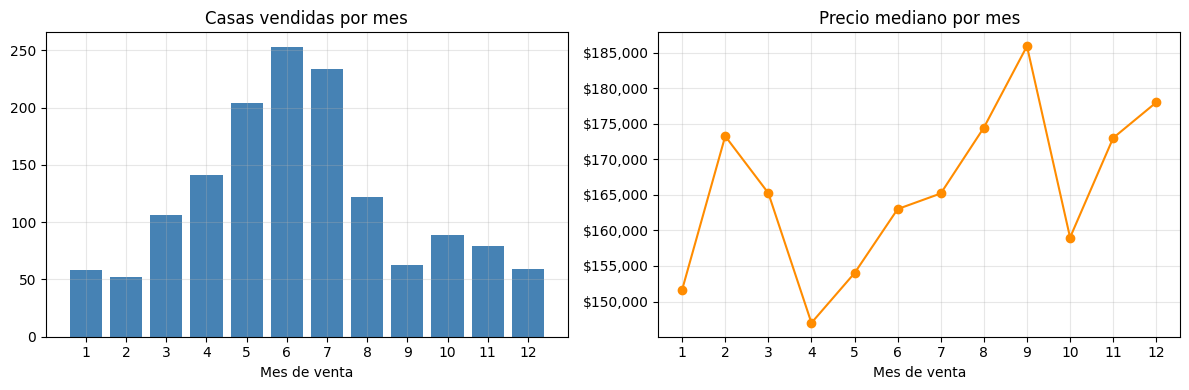

Correlación de Spearman entre MoSold y SalePrice: 0.069


In [15]:
# 3) Casas vendidas y precio mediano por mes de venta.

por_mes = df.groupby('MoSold')['SalePrice'].agg(['count', 'median'])
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
ejes[0].bar(por_mes.index, por_mes['count'], color='steelblue')
ejes[0].set_title('Casas vendidas por mes')
ejes[1].plot(por_mes.index, por_mes['median'], marker='o', color='darkorange')
ejes[1].set_title('Precio mediano por mes')
ejes[1].yaxis.set_major_formatter('${x:,.0f}')
for eje in ejes:
  eje.set_xticks(range(1, 13))
  eje.set_xlabel('Mes de venta')
  eje.grid(alpha=0.3)
plt.tight_layout()
plt.show()
print('Correlación de Spearman entre MoSold y SalePrice: %.3f' % df['MoSold'].corr(df['SalePrice'], method='spearman'))

### **Respuesta**

Transformamos `MoSold` de forma cíclica con seno y coseno y eliminamos la original. El mes sí tiene un patrón, pero en el número de ventas. En junio se vendieron 253 casas y en enero 58. En el precio el efecto es débil. El precio mediano sube y baja entre 147,000 y 186,000 dólares sin un orden claro y su correlación de Spearman con `SalePrice` es de 0.069.

El mes es una variable cíclica. Diciembre y enero están a un mes de distancia, pero como números están a 11. Si se deja numérica, el modelo trata a diciembre como el mes más lejano de enero. Como categórica eso se corrige, pero se agregan 11 columnas para una variable que aporta poco. Con seno y coseno cada mes queda como un punto de un círculo, diciembre queda junto a enero y solo se usan dos columnas. Eliminarla también era una opción razonable por su poco efecto, así que comparamos las cuatro opciones con validación cruzada en la sección de partición, y la cíclica fue la mejor en promedio.

Después de transformarla hay que eliminar la original. Las dos columnas nuevas ya tienen toda su información, y si se deja, el modelo vuelve a ver la distancia falsa entre diciembre y enero. Al valuar una casa se usa el mes en que se hace la valuación, y como el mes casi no mueve el precio, esa elección prácticamente no cambia la estimación. Eliminar la variable también era válido: en otra versión del equipo se eliminó y el resultado fue prácticamente el mismo.

# **Preparación de los datos**

**4.** Realizar un análisis y procesamiento de los datos como consideren sea lo más adecuado. En particular, realicen una limpieza de datos; imputación sobre datos perdidos (media, mediana o moda); decidan qué transformaciones aplicar sobre las variables numéricas, nominales, ordinales, o cíclicas en dado caso. Cada una de estas decisiones se espera sea la mejor de todas las consideradas. Justificar las decisiones tomadas.

      GrLivArea  OverallQual SaleCondition  SalePrice
523        4676           10       Partial     184750
1298       5642           10       Partial     160000


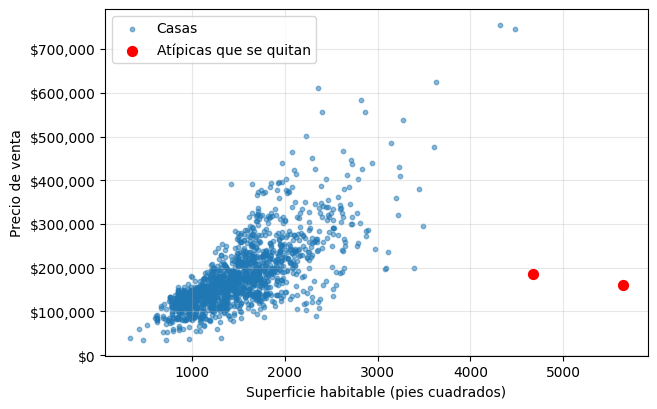

In [16]:
# 4a) Casas atípicas. El autor del conjunto de datos (De Cock, 2011) señala que hay casas de más de 4,000
# pies cuadrados habitables, y dos de ellas se vendieron muy por debajo de lo que corresponde a su tamaño.

atipicas = df[(df['GrLivArea'] > 4000) & (df['SalePrice'] < 300000)]
print(atipicas[['GrLivArea', 'OverallQual', 'SaleCondition', 'SalePrice']])

plt.figure(figsize=(7, 4.5))
plt.scatter(df['GrLivArea'], df['SalePrice'], s=10, alpha=0.5, label='Casas')
plt.scatter(atipicas['GrLivArea'], atipicas['SalePrice'], s=50, color='red', label='Atípicas que se quitan')
plt.xlabel('Superficie habitable (pies cuadrados)')
plt.ylabel('Precio de venta')
plt.gca().yaxis.set_major_formatter('${x:,.0f}')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [17]:
# 4b) Transformaciones fijas. No aprenden nada de los datos, así que aplicarlas antes de la partición no
# filtra información. Lo que sí aprende de los datos (imputaciones y escalamientos) va dentro de un
# Pipeline y solo se ajusta con la parte de entrenamiento.

def preparar(datos, mes='ciclica'):
  d = datos.copy()
  d['AgeHouse'] = ANIO_ACTUAL - d['YearBuilt']
  d['AgeRemod'] = ANIO_ACTUAL - d['YearRemodAdd']
  if mes == 'ciclica':
    d['MoSold_sin'] = np.sin(2 * np.pi * d['MoSold'] / 12)
    d['MoSold_cos'] = np.cos(2 * np.pi * d['MoSold'] / 12)
  elif mes == 'categorica':
    d['MoSold_cat'] = d['MoSold'].astype(str)
  elif mes == 'numerica':
    d['MoSold_num'] = d['MoSold']
  d['MSSubClass'] = d['MSSubClass'].astype(str)   # es un código del tipo de vivienda, no una cantidad
  return d.drop(columns=['Id', 'YrSold', 'YearBuilt', 'YearRemodAdd', 'GarageYrBlt', 'MoSold', 'Utilities'])

print('Valores de Utilities:', df['Utilities'].value_counts().to_dict())

datos = df.drop(index=atipicas.index)
X = preparar(datos.drop(columns='SalePrice'))
y = datos['SalePrice']
print('Casas: %d, variables de entrada: %d' % X.shape)

Valores de Utilities: {'AllPub': 1459, 'NoSeWa': 1}
Casas: 1458, variables de entrada: 77


In [18]:
# 4c) Grupos de variables. En las ordinales el orden sale de la descripción de los datos, y 'Ninguno'
# (la casa no tiene esa característica) queda como el nivel más bajo.

CALIDAD = ['Ninguno', 'Po', 'Fa', 'TA', 'Gd', 'Ex']
ORDINALES = {
  'ExterQual': CALIDAD, 'ExterCond': CALIDAD, 'BsmtQual': CALIDAD, 'BsmtCond': CALIDAD,
  'HeatingQC': CALIDAD, 'KitchenQual': CALIDAD, 'FireplaceQu': CALIDAD,
  'GarageQual': CALIDAD, 'GarageCond': CALIDAD, 'PoolQC': CALIDAD,
  'BsmtExposure': ['Ninguno', 'No', 'Mn', 'Av', 'Gd'],
  'BsmtFinType1': ['Ninguno', 'Unf', 'LwQ', 'Rec', 'BLQ', 'ALQ', 'GLQ'],
  'BsmtFinType2': ['Ninguno', 'Unf', 'LwQ', 'Rec', 'BLQ', 'ALQ', 'GLQ'],
  'GarageFinish': ['Ninguno', 'Unf', 'RFn', 'Fin'],
  'Functional': ['Sal', 'Sev', 'Maj2', 'Maj1', 'Mod', 'Min2', 'Min1', 'Typ']
}
NOMINALES_AUSENCIA = ['Alley', 'GarageType', 'Fence', 'MiscFeature', 'MasVnrType']   # NA = no la tiene
CEROS = ['MasVnrArea']                                                              # sin mampostería, área 0

def numericas(X):
  return [c for c in X.columns if pd.api.types.is_numeric_dtype(X[c]) and c not in CEROS]

def nominales(X):
  return [c for c in X.columns if not pd.api.types.is_numeric_dtype(X[c])
          and c not in ORDINALES and c not in NOMINALES_AUSENCIA]

print('Numéricas: %d' % (len(numericas(X)) + len(CEROS)))
print('Ordinales: %d' % len(ORDINALES))
print('Nominales: %d' % (len(nominales(X)) + len(NOMINALES_AUSENCIA)))

Numéricas: 34
Ordinales: 15
Nominales: 28


In [19]:
# 4d) Dos versiones del preprocesamiento. Los modelos lineales, el MLP y la SVM dependen de la escala, así
# que sus numéricas se transforman con Yeo-Johnson, que reduce el sesgo y estandariza, y sus ordinales se
# estandarizan. A los árboles no les afecta la escala, así que reciben los valores imputados sin más.
# keep_empty_features conserva una columna aunque venga vacía en una muestra chica, por ejemplo PoolQC
# en las primeras casas de la curva de aprendizaje.

def onehot(para_arboles):
  return OneHotEncoder(drop=None if para_arboles else 'first', handle_unknown='infrequent_if_exist',
                       min_frequency=10, sparse_output=False)

def preprocesador(para_arboles):
  escala = [] if para_arboles else [('yeo_johnson', PowerTransformer())]
  escala_ord = [] if para_arboles else [('estandarizar', StandardScaler())]
  ordinal = OrdinalEncoder(categories=list(ORDINALES.values()), handle_unknown='use_encoded_value', unknown_value=-1)
  return ColumnTransformer([
    ('numericas', Pipeline([('imputar', SimpleImputer(strategy='median', keep_empty_features=True))] + escala), numericas),
    ('ceros', Pipeline([('imputar', SimpleImputer(strategy='constant', fill_value=0, keep_empty_features=True))] + escala), CEROS),
    ('ordinales', Pipeline([('imputar', SimpleImputer(strategy='constant', fill_value='Ninguno', keep_empty_features=True)),
                            ('codificar', ordinal)] + escala_ord), list(ORDINALES)),
    ('nominales_ausencia', Pipeline([('imputar', SimpleImputer(strategy='constant', fill_value='Ninguno', keep_empty_features=True)),
                                     ('onehot', onehot(para_arboles))]), NOMINALES_AUSENCIA),
    ('nominales', Pipeline([('imputar', SimpleImputer(strategy='most_frequent', keep_empty_features=True)),
                            ('onehot', onehot(para_arboles))]), nominales)
  ], verbose_feature_names_out=False)

# Todos los modelos se entrenan con log(1 + SalePrice) porque el precio tiene sesgo a la derecha, y sus
# predicciones regresan a dólares, así que las métricas siempre se calculan en dólares.
def con_log(modelo):
  return TransformedTargetRegressor(regressor=modelo, func=np.log1p, inverse_func=np.expm1)

print('Sesgo de SalePrice: %.2f, sesgo de log(1 + SalePrice): %.2f' % (y.skew(), np.log1p(y).skew()))

Sesgo de SalePrice: 1.88, sesgo de log(1 + SalePrice): 0.12


### **Respuesta**

Estas son las decisiones, en el orden del código.

1. Quitamos dos casas de más de 4,000 pies cuadrados, de calidad 10 y vendidas en 184,750 y 160,000 dólares. Las dos son ventas parciales de casas que no estaban terminadas, así que su precio no representa lo que vale una casa de ese tamaño, y con el RMSE dos puntos así jalan al modelo y empeoran sus predicciones para las demás casas grandes. El autor del conjunto de datos recomienda quitar las cuatro casas de más de 4,000 pies cuadrados (De Cock, 2011). Las otras dos se vendieron en 755,000 y 745,000 dólares. La primera es una venta normal y la segunda está registrada como venta anormal (`Abnorml`), pero en las dos el precio es coherente con su tamaño y su calidad, así que las conservamos para que el modelo siga sirviendo para casas de lujo. El costo es un RMSE más alto, porque esas casas caras pesan mucho en la métrica. En una versión alternativa del equipo que quitó las cuatro, el RMSE de validación de la SVM bajó a unos 20,000 dólares; parte de esa diferencia viene de dejar fuera las casas más caras, no de que el modelo fuera mejor.
2. Eliminamos `Id`, que solo identifica el registro, y `Utilities`, que tiene el mismo valor en 1,459 de las 1,460 casas y no aporta información.
3. `MSSubClass` es un código del tipo de vivienda. Aunque viene como número, el tipo 60 no vale el triple que el 20, así que la tratamos como nominal.
4. En la mayoría de las variables con datos perdidos, NA significa que la casa no tiene esa característica, por ejemplo sin callejón, sin sótano, sin chimenea, sin cochera, sin alberca o sin cerca. Ahí imputar con la media, la mediana o la moda inventaría características que la casa no tiene, así que llenamos esos perdidos con la categoría 'Ninguno'. `MasVnrType` aparece con 872 perdidos porque pandas lee como vacío el valor 'None', que en la descripción quiere decir que la casa no tiene chapa de mampostería. Solo 8 faltan de verdad, y en esas casas `MasVnrArea` también falta, así que su área queda en 0.
5. `LotFrontage`, los pies de calle frente al terreno, es el único dato numérico que falta de verdad, en 259 casas. Lo imputamos con la mediana porque la variable tiene sesgo a la derecha y la mediana no se mueve con los terrenos muy grandes, como sí pasa con la media. `Electrical` tiene un solo perdido y lo imputamos con la moda.
6. Las 15 ordinales, como las calidades que van de Po a Ex, las codificamos con el orden de la descripción de los datos y con 'Ninguno' como el nivel más bajo. Así una sola columna conserva que Ex es mejor que Gd, en lugar de crear una columna por nivel.
7. Las 28 nominales van con One-Hot-Encoding. Las categorías con menos de 10 casas se juntan en una sola columna de poco frecuentes, para no crear columnas casi vacías que agregan ruido y que pueden no aparecer en algunos pliegues.
8. Para los modelos lineales, el MLP y la SVM, las 34 numéricas pasan por la transformación de Yeo-Johnson (Yeo y Johnson, 2000), que reduce el sesgo de variables como `LotArea` o `GrLivArea` y las deja en la misma escala, y las ordinales se estandarizan. Estos modelos dependen de la escala de las variables. A los árboles no les afecta, así que ahí solo se imputan.
9. El precio tiene un sesgo a la derecha de 1.88 por las casas caras. Todos los modelos aprenden log(1 + SalePrice), que baja el sesgo a 0.12, y su predicción regresa a dólares antes de calcular cualquier métrica.
10. La única variable cíclica es `MoSold`, que ya quedó con seno y coseno en la pregunta 3.

Para evitar el filtrado de información, todo lo que aprende de los datos, como medianas, modas, los parámetros de Yeo-Johnson y las categorías, va dentro de un Pipeline, y en cada pliegue de la validación cruzada se ajusta solo con la parte de entrenamiento. Antes de la partición solo se aplican transformaciones fijas que no dependen de las demás casas, como restar el año a 2026 o calcular el seno del mes. Al final quedan 177 columnas para los modelos lineales, el MLP y la SVM, y 205 para los árboles, que no quitan ninguna categoría al codificar.

**5.** En particular, expliquen la decisión tomada con los datos perdidos de las variables “PoolQc” y “GarageType”.

In [20]:
# 5) PoolQC y GarageType. Los datos perdidos coinciden con las casas sin alberca y sin cochera.

print('PoolQC perdidos: %d, casas con PoolArea = 0: %d' % (df['PoolQC'].isna().sum(), (df['PoolArea'] == 0).sum()))
print('Valores de PoolQC:', df['PoolQC'].value_counts().to_dict())
print()
print('GarageType perdidos: %d, casas con GarageArea = 0: %d' % (df['GarageType'].isna().sum(), (df['GarageArea'] == 0).sum()))
print('Valores de GarageType:', df['GarageType'].value_counts().to_dict())
print()
print('Precio mediano con y sin cochera:')
print(df.groupby(np.where(df['GarageType'].isna(), 'Sin cochera', 'Con cochera'))['SalePrice'].median())

PoolQC perdidos: 1453, casas con PoolArea = 0: 1453
Valores de PoolQC: {'Gd': 3, 'Ex': 2, 'Fa': 2}

GarageType perdidos: 81, casas con GarageArea = 0: 81
Valores de GarageType: {'Attchd': 870, 'Detchd': 387, 'BuiltIn': 88, 'Basment': 19, 'CarPort': 9, '2Types': 6}

Precio mediano con y sin cochera:
Con cochera    167500.0
Sin cochera    100000.0
Name: SalePrice, dtype: float64


### **Respuesta**

En las dos variables NA no es un dato que falte, quiere decir que la casa no tiene alberca o no tiene cochera, y los datos lo confirman. Las 1,453 casas sin `PoolQC` son exactamente las 1,453 con `PoolArea` igual a 0, y las 81 sin `GarageType` son las 81 con `GarageArea` igual a 0.

Por eso no usamos la media, la mediana ni la moda. Con la moda, por ejemplo, las 1,453 casas sin alberca quedarían con una alberca de calidad Gd, que es la calidad más común entre las 7 que sí tienen. En las dos variables llenamos los perdidos con la categoría 'Ninguno'.

`PoolQC` es ordinal, así que 'Ninguno' queda como el nivel más bajo, por debajo de Po. Con solo 7 albercas casi no aporta, pero la dejamos porque así se lee bien el dato y no le hace daño a ningún modelo. `GarageType` es nominal, así que 'Ninguno' se vuelve su propia columna en el One-Hot. Esa columna sí importa, porque el precio mediano de una casa sin cochera es de 100,000 dólares y el de una con cochera es de 167,500.

**6.** Para las variables nominales en las cuales hayan decidido aplicar la transformación One-Hot-Encoding, explicar si debe hacerse diferencia en relación con el valor del hiperparámetro “drop” cuando se usa en un modelo basado en árboles, o con en el resto de los modelos.

### **Respuesta**

Sí hay diferencia. En la regresión lineal sin regularización hay que quitar una categoría de cada variable con `drop='first'`. Si se dejan todas, las columnas de una misma variable siempre suman 1, igual que la columna del intercepto, y la matriz queda con colinealidad perfecta. Así los coeficientes no tienen una solución única, lo que se conoce como la trampa de las variables ficticias. La categoría que se quita queda como referencia y cada coeficiente se lee como la diferencia contra ella.

En Ridge, Lasso, Elastic Net, el MLP y la SVM la regularización evita ese problema, así que quitar una categoría no es obligatorio, aunque tampoco estorba. Para no tener dos versiones del preprocesamiento usamos `drop='first'` en todos ellos.

En los modelos basados en árboles conviene no quitar ninguna, con `drop=None`. Un árbol corta con una columna a la vez, así que con todas las columnas puede separar cualquier categoría en un solo corte. Si se quita una, esa categoría solo se reconoce cuando todas las demás columnas valen 0 y el árbol necesita varios cortes para llegar a ella. Además su importancia se reparte entre las otras columnas y el análisis de factores se vuelve más difícil de leer.

Una opción intermedia es `drop='if_binary'`, que solo quita una columna en las variables con dos categorías, como `Street` o `CentralAir`. En los árboles eso no estorba, porque con una sola columna ya se sabe cuál de las dos categorías tiene la casa, y se elimina una columna redundante. En las variables con más categorías se conservan todas.

# **Partición y modelo base**

**7.** Realizar una partición en entrenamiento (train), validación (val) y prueba (test) con el porcentaje que consideren más adecuado. En dado caso, si deciden usar Validación-Cruzada (con las secciones/folds que mejor consideren), entonces se entiende que aquí solo sería necesario particionarlo en dos.

In [21]:
# 7) Partición 80-20 estratificada por quintiles del precio, para que Train y Test tengan la misma mezcla
# de casas baratas y caras. Los hiperparámetros se eligen con validación cruzada de 5 pliegues dentro de
# Train, así que no hace falta un conjunto de validación aparte. Test se usa una sola vez, al final.

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE,
                                                    stratify=pd.qcut(y, 5, labels=False))
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print('Train: %d casas, precio mediano $%s' % (len(y_train), format(int(y_train.median()), ',')))
print('Test:  %d casas, precio mediano $%s' % (len(y_test), format(int(y_test.median()), ',')))
for nombre, para_arboles in [('lineales, MLP y SVM', False), ('árboles', True)]:
  columnas = preprocesador(para_arboles).fit(X_train).get_feature_names_out()
  print('Columnas después del preprocesamiento para %s: %d' % (nombre, len(columnas)))

Train: 1166 casas, precio mediano $163,000
Test:  292 casas, precio mediano $161,500
Columnas después del preprocesamiento para lineales, MLP y SVM: 177
Columnas después del preprocesamiento para árboles: 205


### **Respuesta**

Separamos el 80% de las casas para entrenamiento y el 20% para prueba, 1,166 y 292 casas. Con solo 1,458 casas, apartar además un conjunto de validación dejaría pocos datos para entrenar, y la medición dependería mucho de qué casas cayeron en cada parte. Por eso los hiperparámetros se eligen con validación cruzada de 5 pliegues dentro de Train. Cada casa de Train sirve una vez para validar y cuatro veces para entrenar, y el resultado es el promedio de los 5 pliegues.

La partición está estratificada por quintiles del precio para que Train y Test tengan la misma mezcla de casas baratas y caras, y sus precios medianos quedaron en 163,000 y 161,500 dólares. Test no se usa para elegir nada, solo para medir al final.

**8.** Con relación a la métrica de la raíz del error cuadrático medio (RMSE), obtener el desempeño del modelo base o ingenuo.

In [22]:
# 8) Modelo ingenuo: predice siempre el precio promedio de Train.

METRICAS = {'rmse': 'neg_root_mean_squared_error', 'mae': 'neg_mean_absolute_error',
            'r2': 'r2', 'mape': 'neg_mean_absolute_percentage_error'}
resultados, modelos = {}, {}

def fila_cv(r, tiempo):
  return {'RMSE Train': -r['train_rmse'].mean(), 'RMSE Val': -r['test_rmse'].mean(),
          'MAE Val': -r['test_mae'].mean(), 'R2 Val': r['test_r2'].mean(),
          'MAPE Val': -r['test_mape'].mean(), 'Tiempo de entrenamiento (s)': tiempo}

def tabla(nombres):
  t = pd.DataFrame(resultados).T.loc[nombres]
  return t.style.format({'RMSE Train': '${:,.0f}', 'RMSE Val': '${:,.0f}', 'MAE Val': '${:,.0f}',
                         'R2 Val': '{:.3f}', 'MAPE Val': '{:.1%}', 'Tiempo de entrenamiento (s)': '{:.2f}'})

ingenuo = DummyRegressor(strategy='mean')
r = cross_validate(ingenuo, X_train, y_train, cv=cv, scoring=METRICAS, return_train_score=True)
inicio = time.perf_counter()
ingenuo.fit(X_train, y_train)
resultados['Modelo ingenuo'] = fila_cv(r, time.perf_counter() - inicio)
modelos['Modelo ingenuo'] = ingenuo
print('RMSE del modelo ingenuo en Test: $%s' % format(round(root_mean_squared_error(y_test, ingenuo.predict(X_test))), ','))
tabla(['Modelo ingenuo'])

RMSE del modelo ingenuo en Test: $67,325


,RMSE Train,RMSE Val,MAE Val,R2 Val,MAPE Val,Tiempo de entrenamiento (s)
Modelo ingenuo,"$82,183","$81,698","$58,919",-0.010,36.6%,0.00


### **Respuesta**

El modelo ingenuo predice para cualquier casa el precio promedio de Train. Su RMSE es de 81,698 dólares en validación cruzada y de 67,325 en Test, con un R² de prácticamente 0 y un MAPE de 36.6%. Es la referencia mínima que cualquier modelo tiene que superar, porque para predecir el promedio no hace falta saber nada de la casa.

### **Comprobación de MoSold**

In [23]:
# Comprobación de la decisión sobre MoSold (pregunta 3). Se comparan las cuatro opciones con validación
# cruzada en Train, con una regresión Ridge y con un XGBoost con valores fijos.

filas = []
for opcion in ['numerica', 'categorica', 'ciclica', 'eliminar']:
  Xo = preparar(datos.drop(columns='SalePrice'), mes=opcion).loc[X_train.index]
  for nombre, modelo, para_arboles in [
      ('Ridge', Ridge(alpha=10), False),
      ('XGBoost', XGBRegressor(n_estimators=600, learning_rate=0.05, max_depth=3, subsample=0.8,
                               colsample_bytree=0.5, n_jobs=1, random_state=RANDOM_STATE), True)]:
    pipe = con_log(Pipeline([('prep', preprocesador(para_arboles)), ('modelo', modelo)]))
    r = cross_validate(pipe, Xo, y_train, cv=cv, scoring='neg_root_mean_squared_error', n_jobs=-1)
    filas.append({'Opción para MoSold': opcion, 'Modelo': nombre, 'RMSE Val': -r['test_score'].mean()})

(pd.DataFrame(filas).pivot(index='Opción para MoSold', columns='Modelo', values='RMSE Val')
   .style.format('${:,.0f}'))

Modelo,Ridge,XGBoost
Opción para MoSold,,
categorica,"$22,508","$23,946"
ciclica,"$22,537","$23,876"
eliminar,"$22,589","$23,999"
numerica,"$22,613","$24,324"


### **Respuesta**

Las cuatro opciones quedan casi empatadas. La diferencia entre la mejor y la peor es de 105 dólares de RMSE con Ridge y de 448 con XGBoost, menos del 2%, lo que confirma que el mes casi no influye en el precio. La transformación cíclica es la mejor con XGBoost y la segunda con Ridge, a 29 dólares de la categórica, que usa 11 columnas en lugar de 2. Por eso nos quedamos con seno y coseno, que funciona bien en los dos modelos y respeta que el mes es cíclico.

# **Modelos**

**9.** Deberán llevar a cabo el entrenamiento y ajuste de hiperparámetros de los modelos considerando como métrica de referencia la RMSE y evitando filtrado de información. Lleven el entrenamiento y ajuste para cada modelo por separado y mostrando en cada caso la gráfica de curvas de aprendizaje. Sin embargo, mostrar de manera tabular también el resultado de RMSE, MAE, R², MAPE y el tiempo de entrenamiento.

In [24]:
# 9) Funciones comunes. Cada modelo es un Pipeline con su preprocesamiento, así que en cada pliegue la
# imputación y las transformaciones se ajustan solo con la parte de entrenamiento y no hay filtrado de
# información. La búsqueda elige los hiperparámetros con el menor RMSE de validación cruzada, y el tiempo
# de entrenamiento es lo que tarda en reentrenarse el modelo elegido con todo Train.

def ajustar(nombre, modelo, rejilla, para_arboles, n_iter=None):
  pipe = con_log(Pipeline([('prep', preprocesador(para_arboles)), ('modelo', modelo)]))
  rejilla = {'regressor__modelo__' + k: v for k, v in rejilla.items()}
  if n_iter:
    busqueda = RandomizedSearchCV(pipe, rejilla, n_iter=n_iter, cv=cv, scoring=METRICAS, refit='rmse',
                                  return_train_score=True, n_jobs=-1, random_state=RANDOM_STATE)
  else:
    busqueda = GridSearchCV(pipe, rejilla, cv=cv, scoring=METRICAS, refit='rmse',
                            return_train_score=True, n_jobs=-1)
  busqueda.fit(X_train, y_train)
  i, r = busqueda.best_index_, busqueda.cv_results_
  modelos[nombre] = busqueda.best_estimator_
  resultados[nombre] = {'RMSE Train': -r['mean_train_rmse'][i], 'RMSE Val': -r['mean_test_rmse'][i],
                        'MAE Val': -r['mean_test_mae'][i], 'R2 Val': r['mean_test_r2'][i],
                        'MAPE Val': -r['mean_test_mape'][i], 'Tiempo de entrenamiento (s)': busqueda.refit_time_}
  mejores = {k.replace('regressor__modelo__', ''): v for k, v in busqueda.best_params_.items()}
  print('%s, hiperparámetros elegidos: %s' % (nombre, mejores if mejores else 'sin hiperparámetros'))

def curva(nombre, eje=None, escala_log=False):
  tam, tr, va = learning_curve(modelos[nombre], X_train, y_train, cv=cv, n_jobs=-1,
                               scoring='neg_root_mean_squared_error', train_sizes=np.linspace(0.1, 1.0, 8))
  eje = eje or plt.subplots(figsize=(8, 4.5))[1]
  for valores, etiqueta, color in [(-tr, 'Entrenamiento', 'tab:blue'), (-va, 'Validación', 'tab:orange')]:
    media, desv = valores.mean(axis=1), valores.std(axis=1)
    eje.plot(tam, media, marker='o', color=color, label=etiqueta)
    eje.fill_between(tam, media - desv, media + desv, color=color, alpha=0.15)
  eje.set_title('Curva de aprendizaje: %s' % nombre)
  eje.set_xlabel('Casas usadas para entrenar')
  eje.set_ylabel('RMSE (escala logarítmica)' if escala_log else 'RMSE')
  if escala_log:
    eje.set_yscale('log')
  eje.yaxis.set_major_formatter('${x:,.0f}')
  eje.legend()
  eje.grid(alpha=0.3)

### **a. Regresión lineal múltiple**

Regresión lineal, hiperparámetros elegidos: sin hiperparámetros
Ridge, hiperparámetros elegidos: {'alpha': 3}
Lasso, hiperparámetros elegidos: {'alpha': 0.0005}
Elastic Net, hiperparámetros elegidos: {'alpha': 0.0005, 'l1_ratio': 0.8}


,RMSE Train,RMSE Val,MAE Val,R2 Val,MAPE Val,Tiempo de entrenamiento (s)
Regresión lineal,"$17,880","$23,111","$14,992",0.914,8.5%,0.69
Ridge,"$18,431","$22,532","$14,394",0.920,8.1%,0.17
Lasso,"$19,588","$22,615","$14,381",0.919,8.0%,0.18
Elastic Net,"$19,328","$22,608","$14,374",0.919,8.0%,0.20


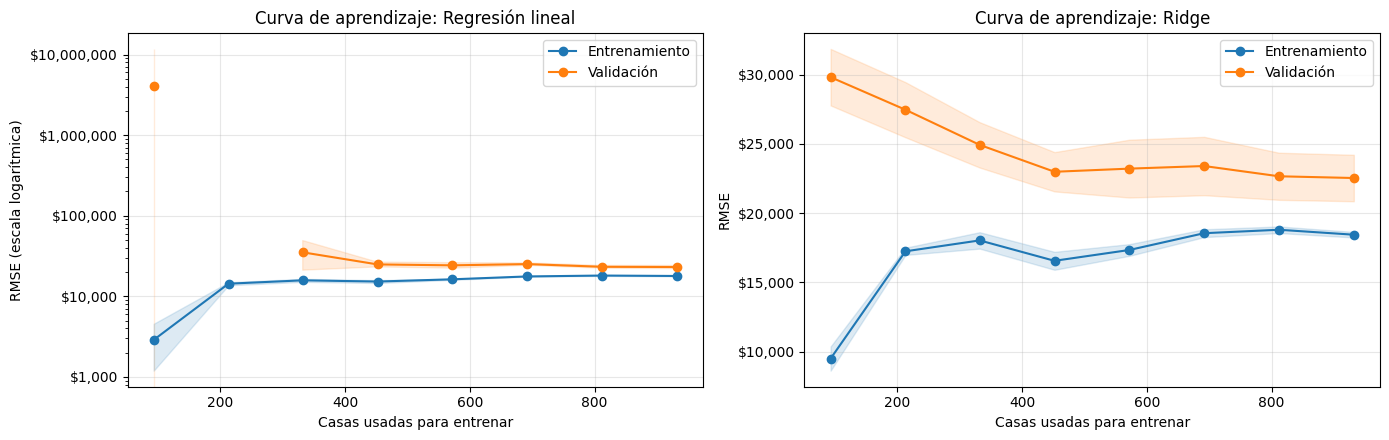

In [25]:
# 9a) Regresión lineal múltiple sin regularización y con regularización Ridge, Lasso y Elastic Net.

ajustar('Regresión lineal', LinearRegression(), {}, para_arboles=False)
ajustar('Ridge', Ridge(), {'alpha': [1, 3, 10, 30, 100]}, para_arboles=False)
ajustar('Lasso', Lasso(max_iter=50000), {'alpha': [0.0002, 0.0005, 0.001, 0.002, 0.005]}, para_arboles=False)
ajustar('Elastic Net', ElasticNet(max_iter=50000),
        {'alpha': [0.0005, 0.001, 0.002, 0.005], 'l1_ratio': [0.2, 0.5, 0.8]}, para_arboles=False)

LINEALES = ['Regresión lineal', 'Ridge', 'Lasso', 'Elastic Net']
mejor_lineal = min(LINEALES[1:], key=lambda n: resultados[n]['RMSE Val'])
display(tabla(LINEALES))

fig, ejes = plt.subplots(1, 2, figsize=(14, 4.5))
curva('Regresión lineal', ejes[0], escala_log=True)   # con pocas casas su error se dispara
curva(mejor_lineal, ejes[1])
plt.tight_layout()
plt.show()

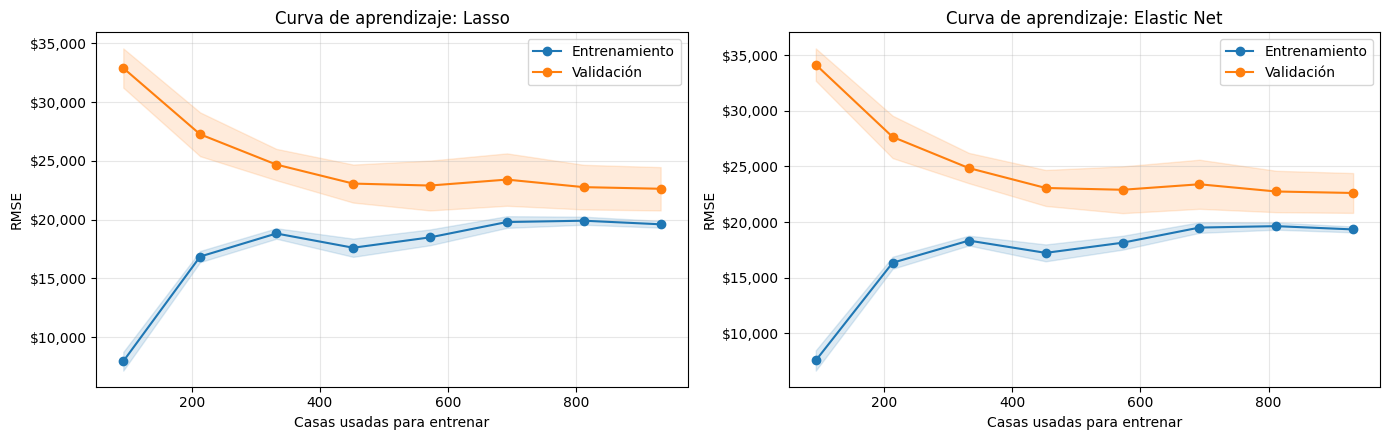

In [26]:
# Curvas de aprendizaje de Lasso y Elastic Net, para mostrar la curva de cada modelo lineal ajustado.

fig, ejes = plt.subplots(1, 2, figsize=(14, 4.5))
curva('Lasso', ejes[0])
curva('Elastic Net', ejes[1])
plt.tight_layout()
plt.show()

### **Respuesta**

La regresión lineal sin regularización tiene un RMSE de 17,880 dólares en entrenamiento y de 23,111 en validación. Con 177 columnas y unas 933 casas por pliegue se ajusta de más a los datos de entrenamiento. Su curva de aprendizaje lo muestra mejor. Con 93 casas, menos que sus 177 columnas, el error de validación se dispara a varios millones de dólares, y por eso esa gráfica va en escala logarítmica.

Las tres versiones con regularización mejoran la validación y reducen la brecha. La mejor es Ridge (Hoerl y Kennard, 1970) con `alpha` de 3, con 22,532 dólares de RMSE en validación, un R² de 0.920 y un MAPE de 8.1%. Lasso y Elastic Net quedan a menos de 90 dólares, y sus curvas de aprendizaje, en la celda anterior, se comportan igual que la de Ridge. En la curva de Ridge el error de validación baja conforme hay más casas y la brecha con entrenamiento es de unos 4,100 dólares, así que no está sobreentrenado. Tampoco está subentrenado, porque su error es poco más de la cuarta parte del modelo ingenuo.

### **b. Árbol de decisión**

Árbol de decisión, hiperparámetros elegidos: {'max_depth': 8, 'min_samples_leaf': 5}


,RMSE Train,RMSE Val,MAE Val,R2 Val,MAPE Val,Tiempo de entrenamiento (s)
Árbol de decisión,"$20,690","$36,130","$24,749",0.802,14.0%,0.17


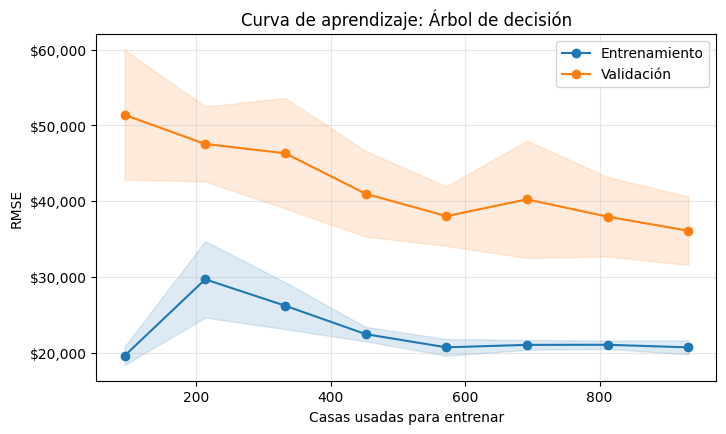

In [27]:
# 9b) Árbol de decisión.

ajustar('Árbol de decisión', DecisionTreeRegressor(random_state=RANDOM_STATE),
        {'max_depth': [4, 6, 8, 10, None], 'min_samples_leaf': [1, 5, 10, 20]}, para_arboles=True)
display(tabla(['Árbol de decisión']))
curva('Árbol de decisión')
plt.show()

### **Respuesta**

El árbol de decisión es el peor de los seis, con 36,130 dólares de RMSE en validación, un R² de 0.802 y un MAPE de 14.0%. La búsqueda eligió una profundidad máxima de 8 y al menos 5 casas por hoja, que es lo que frena un poco el sobreentrenamiento. Aun así la brecha entre entrenamiento y validación es de unos 15,400 dólares, de las más grandes junto con la del bosque aleatorio. Un solo árbol da el mismo precio a todas las casas de una hoja y cambia mucho según las casas que le tocan. En su curva el error de validación sigue bajando con más casas, que es la señal de un modelo con mucha varianza.

### **c. Bosque aleatorio**

Bosque aleatorio, hiperparámetros elegidos: {'max_features': 0.33, 'min_samples_leaf': 1}


,RMSE Train,RMSE Val,MAE Val,R2 Val,MAPE Val,Tiempo de entrenamiento (s)
Bosque aleatorio,"$10,742","$27,796","$16,934",0.882,9.3%,4.09


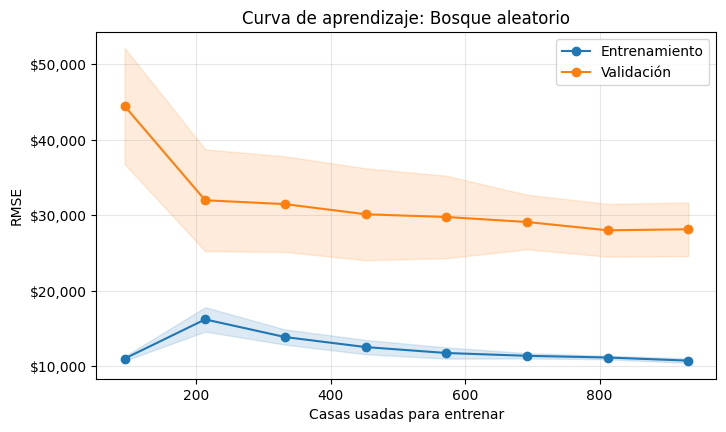

In [28]:
# 9c) Bosque aleatorio.

ajustar('Bosque aleatorio', RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=1),
        {'max_features': [0.2, 0.33, 0.5, 1.0], 'min_samples_leaf': [1, 2, 4]}, para_arboles=True)
display(tabla(['Bosque aleatorio']))
curva('Bosque aleatorio')
plt.show()

### **Respuesta**

El bosque aleatorio promedia 300 árboles, cada uno entrenado con una muestra distinta de casas y con un tercio de las variables en cada corte (Breiman, 2001). Eso baja el RMSE de validación de 36,130 dólares con un solo árbol a 27,796, con un R² de 0.882 y un MAPE de 9.3%. La brecha con entrenamiento sigue siendo grande porque cada árbol crece hasta hojas de una sola casa, algo normal en un bosque aleatorio. Lo que importa es la validación, y ahí queda lejos de los modelos lineales. Su predicción sigue siendo un promedio de escalones, mientras que aquí el precio crece de forma suave con la superficie y la calidad, que es justo lo que los modelos lineales capturan bien.

### **d. XGBoost**

XGBoost, hiperparámetros elegidos: {'subsample': 0.6, 'reg_lambda': 1, 'n_estimators': 600, 'min_child_weight': 3, 'max_depth': 3, 'learning_rate': 0.05, 'colsample_bytree': 0.3}


,RMSE Train,RMSE Val,MAE Val,R2 Val,MAPE Val,Tiempo de entrenamiento (s)
XGBoost,"$9,413","$23,420","$14,397",0.916,8.1%,0.48


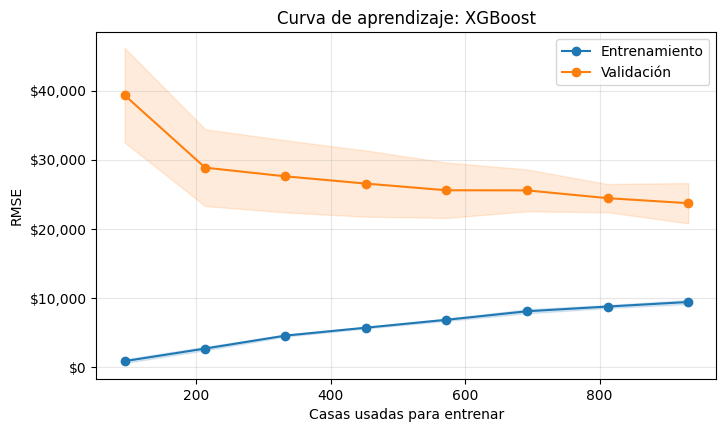

In [29]:
# 9d) XGBoost. La rejilla es grande, así que se prueban 40 combinaciones al azar.

ajustar('XGBoost', XGBRegressor(random_state=RANDOM_STATE, n_jobs=1),
        {'n_estimators': [300, 600, 1000, 1500], 'learning_rate': [0.01, 0.03, 0.05, 0.1],
         'max_depth': [2, 3, 4, 5], 'min_child_weight': [1, 3, 5], 'subsample': [0.6, 0.8, 1.0],
         'colsample_bytree': [0.3, 0.5, 0.7], 'reg_lambda': [1, 5]}, para_arboles=True, n_iter=40)
display(tabla(['XGBoost']))
curva('XGBoost')
plt.show()

### **Respuesta**

XGBoost construye árboles poco profundos uno tras otro, y cada uno corrige el error de los anteriores (Chen y Guestrin, 2016). La búsqueda eligió 600 árboles de profundidad 3 con tasa de aprendizaje de 0.05, y en cada árbol solo el 60% de las casas y el 30% de las variables, lo que ayuda a no sobreentrenar. Mejora mucho al bosque aleatorio, con 23,420 dólares de RMSE en validación, un R² de 0.916 y un MAPE de 8.1%. La brecha con entrenamiento es grande, de unos 14,000 dólares, pero en la curva el error de entrenamiento sube y el de validación baja conforme hay más casas, así que las dos líneas se acercan y con más datos mejoraría.

### **e. Red neuronal MLP**

MLP, hiperparámetros elegidos: {'regressor__learning_rate_init': 0.003, 'regressor__hidden_layer_sizes': (128,), 'regressor__alpha': 1}


,RMSE Train,RMSE Val,MAE Val,R2 Val,MAPE Val,Tiempo de entrenamiento (s)
MLP,"$14,223","$23,253","$14,797",0.914,8.3%,1.12


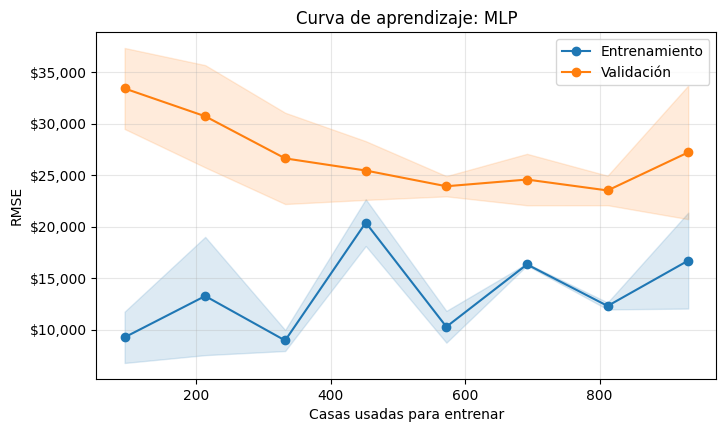

In [30]:
# 9e) Red neuronal de perceptrón multicapa. La salida también se estandariza para que la red entrene mejor,
# y se detiene sola cuando deja de mejorar en una parte de sus datos de entrenamiento.

mlp = TransformedTargetRegressor(regressor=MLPRegressor(max_iter=3000, early_stopping=True, n_iter_no_change=30,
                                                        random_state=RANDOM_STATE),
                                 transformer=StandardScaler())
ajustar('MLP', mlp,
        {'regressor__hidden_layer_sizes': [(32,), (64,), (128,), (64, 32)], 'regressor__alpha': [0.1, 1, 3, 10],
         'regressor__learning_rate_init': [0.001, 0.003]}, para_arboles=False, n_iter=20)
display(tabla(['MLP']))
curva('MLP')
plt.show()

### **Respuesta**

La red quedó con una capa oculta de 128 neuronas. Con tan pocas casas una red se sobreentrena fácil, por eso la búsqueda eligió una regularización fuerte, con `alpha` de 1, y el entrenamiento se detiene solo cuando deja de mejorar. Tiene 23,253 dólares de RMSE en validación, un R² de 0.914 y un MAPE de 8.3%, cerca de XGBoost. La curva de entrenamiento sube y baja porque con cada tamaño de muestra la red se detiene en un punto distinto. La de validación baja hasta unas 800 casas, pero vuelve a subir en el último punto y con una banda muy ancha. Es el modelo menos estable de los seis y el más difícil de explicar.

### **f. Máquina de vector soporte**

SVM, hiperparámetros elegidos: {'C': 10, 'epsilon': 0.05, 'gamma': 0.0005}


,RMSE Train,RMSE Val,MAE Val,R2 Val,MAPE Val,Tiempo de entrenamiento (s)
SVM,"$17,251","$22,460","$13,856",0.922,7.8%,0.28


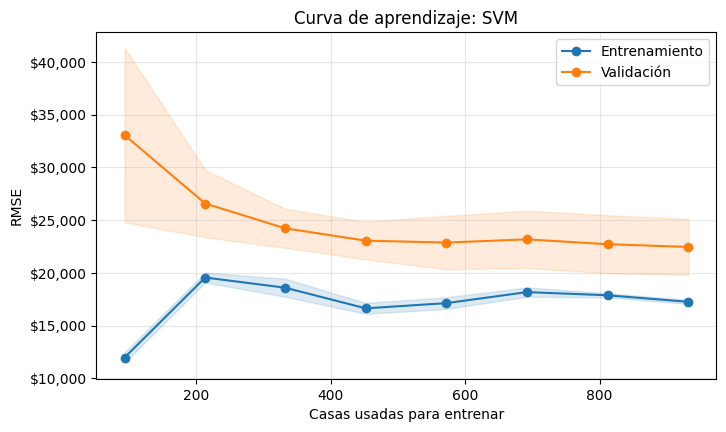

In [31]:
# 9f) Máquina de vector soporte con kernel RBF.

ajustar('SVM', SVR(kernel='rbf'),
        {'C': [0.3, 1, 3, 10], 'epsilon': [0.005, 0.01, 0.05], 'gamma': ['scale', 0.0005, 0.001, 0.003]},
        para_arboles=False)
display(tabla(['SVM']))
curva('SVM')
plt.show()

### **Respuesta**

La SVM con kernel RBF (Drucker et al., 1997) es el mejor modelo individual, con 22,460 dólares de RMSE en validación, un R² de 0.922 y un MAPE de 7.8%. El `gamma` que eligió la búsqueda es muy pequeño, de 0.0005, así que el kernel es muy suave y el modelo se comporta casi como una regresión lineal con un poco de curvatura. Eso explica por qué queda tan cerca de Ridge. El `epsilon` de 0.05 está en escala logarítmica y quiere decir que no castiga errores menores a cerca de 5% del precio, lo que lo hace menos sensible a casas raras. Su brecha con entrenamiento es de unos 5,200 dólares y en la curva las dos líneas se acercan, sin señales de sobreentrenamiento fuerte. Una limitación: `C=10` es el valor más alto de la rejilla y `gamma=0.0005` el más bajo, así que el óptimo podría estar fuera de ella. En la versión alternativa del equipo, con una rejilla más amplia, el mejor resultado quedó en `C=30` y `gamma=0.0003`, dentro del rango. Esto sugiere que ampliar la rejilla daría una mejora pequeña, sin cambiar las conclusiones.

### **Comparación de los seis modelos**

In [32]:
# Resumen de los seis modelos con validación cruzada en Train, ordenados por RMSE de validación.
# De los lineales queda el mejor con regularización.

FAMILIAS = [mejor_lineal, 'Árbol de decisión', 'Bosque aleatorio', 'XGBoost', 'MLP', 'SVM']
orden = sorted(FAMILIAS, key=lambda n: resultados[n]['RMSE Val'])
tabla(orden + ['Regresión lineal', 'Modelo ingenuo'])

,RMSE Train,RMSE Val,MAE Val,R2 Val,MAPE Val,Tiempo de entrenamiento (s)
SVM,"$17,251","$22,460","$13,856",0.922,7.8%,0.28
Ridge,"$18,431","$22,532","$14,394",0.920,8.1%,0.17
MLP,"$14,223","$23,253","$14,797",0.914,8.3%,1.12
XGBoost,"$9,413","$23,420","$14,397",0.916,8.1%,0.48
Bosque aleatorio,"$10,742","$27,796","$16,934",0.882,9.3%,4.09
Árbol de decisión,"$20,690","$36,130","$24,749",0.802,14.0%,0.17
Regresión lineal,"$17,880","$23,111","$14,992",0.914,8.5%,0.69
Modelo ingenuo,"$82,183","$81,698","$58,919",-0.010,36.6%,0.00


### **Respuesta**

Los seis modelos superan por mucho al ingenuo. Los cuatro mejores son la SVM, Ridge, el MLP y XGBoost, todos entre 22,400 y 23,500 dólares de RMSE en validación, con R² de 0.91 a 0.92 y MAPE de alrededor de 8%, es decir que en promedio se equivocan por el 8% del precio de la casa. El bosque aleatorio y sobre todo el árbol de decisión quedan atrás.

Que Ridge y una SVM con kernel muy suave queden arriba dice algo del problema. Con el precio en logaritmo y las variables transformadas, la relación entre las características y el precio es casi lineal, y con 1,166 casas los modelos más flexibles no tienen mucho más que aprender. Todos se entrenan en pocos segundos con scikit-learn (Pedregosa et al., 2011), así que el tiempo no pesa para elegir entre ellos. Los tiempos de la tabla cambian un poco en cada ejecución porque dependen de qué tan ocupada esté la computadora.

# **Análisis de factores**

**10.** Con base al mejor modelo obtenido realizar un análisis de factores, con la interpretación en base al contexto del problema.

Mejor modelo: SVM


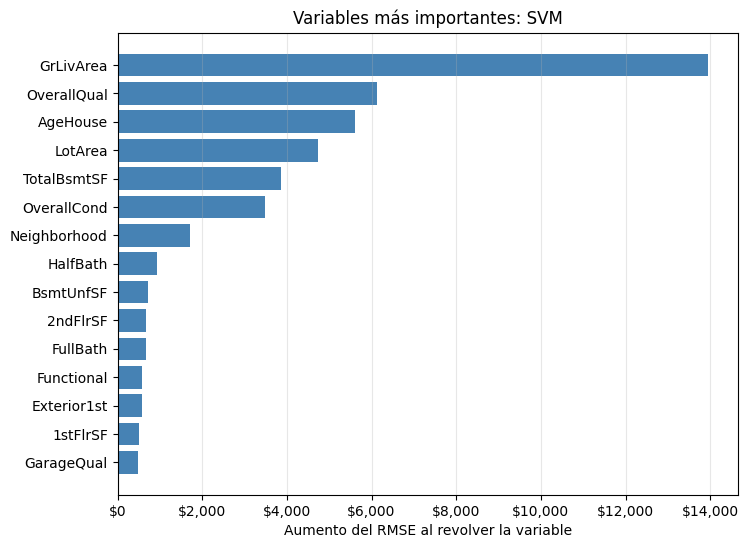

,Aumento del RMSE (USD)
GrLivArea,"$13,950"
OverallQual,"$6,117"
AgeHouse,"$5,597"
LotArea,"$4,732"
TotalBsmtSF,"$3,857"
OverallCond,"$3,484"
Neighborhood,"$1,706"
HalfBath,$928
BsmtUnfSF,$728
2ndFlrSF,$677


In [33]:
# 10) Factores del mejor modelo. La importancia por permutación mide cuánto sube el RMSE en Test cuando se
# revuelven los valores de una variable original, así que se lee directamente en dólares.

mejor_nombre = orden[0]
mejor = modelos[mejor_nombre]
imp = permutation_importance(mejor, X_test, y_test, scoring='neg_root_mean_squared_error',
                             n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
importancia = pd.Series(imp.importances_mean, index=X_test.columns).sort_values(ascending=False)
print('Mejor modelo: %s' % mejor_nombre)

top = importancia.head(15)[::-1]
plt.figure(figsize=(8, 6))
plt.barh(top.index, top.values, color='steelblue')
plt.xlabel('Aumento del RMSE al revolver la variable')
plt.gca().xaxis.set_major_formatter('${x:,.0f}')
plt.title('Variables más importantes: %s' % mejor_nombre)
plt.grid(axis='x', alpha=0.3)
plt.show()

importancia.head(15).to_frame('Aumento del RMSE (USD)').style.format('${:,.0f}')

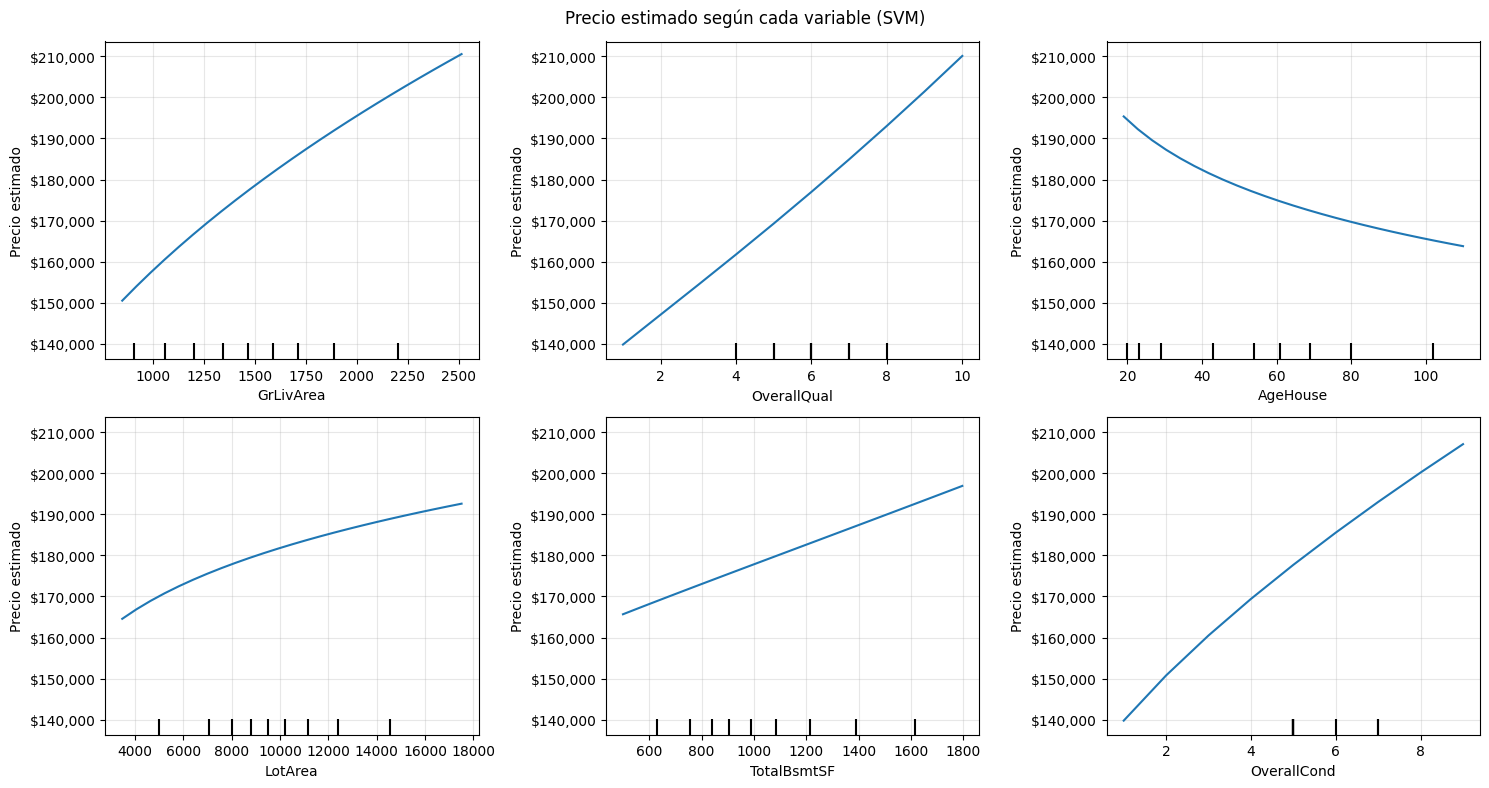

,Percentil 10,Percentil 90,Precio en el percentil 10,Precio en el percentil 90,Diferencia
Variable,,,,,
GrLivArea,906,"2,198","$153,431","$201,519","$48,087"
OverallQual,4,8,"$161,787","$193,065","$31,278"
AgeHouse,20,102,"$194,486","$165,198","$-29,288"
LotArea,"5,032","14,538","$170,185","$188,840","$18,655"
TotalBsmtSF,630,"1,615","$168,875","$192,507","$23,632"
OverallCond,5,7,"$177,688","$192,988","$15,300"


In [34]:
# Efecto promedio de las seis variables numéricas más importantes sobre el precio estimado (dependencia
# parcial). Cada curva muestra cómo cambia el precio cuando se mueve esa variable y las demás se quedan igual.

top_num = [c for c in importancia.index if c in numericas(X_train)][:6]
fig, ejes = plt.subplots(2, 3, figsize=(15, 8))
X_pdp = X_train.astype({c: float for c in numericas(X_train)})   # la gráfica pide columnas decimales
PartialDependenceDisplay.from_estimator(mejor, X_pdp, top_num, ax=ejes.ravel(), grid_resolution=25)
for eje in ejes.ravel():
  eje.set_ylabel('Precio estimado')
  eje.yaxis.set_major_formatter('${x:,.0f}')
  eje.grid(alpha=0.3)
plt.suptitle('Precio estimado según cada variable (%s)' % mejor_nombre)
plt.tight_layout()
plt.show()

# Precio estimado cuando la variable está en su percentil 10 y en su percentil 90.
filas = []
for c in top_num:
  bajo, alto = X_pdp[c].quantile([0.10, 0.90])
  promedio = [mejor.predict(X_pdp.assign(**{c: v})).mean() for v in (bajo, alto)]
  filas.append({'Variable': c, 'Percentil 10': bajo, 'Percentil 90': alto, 'Precio en el percentil 10': promedio[0],
                'Precio en el percentil 90': promedio[1], 'Diferencia': promedio[1] - promedio[0]})
(pd.DataFrame(filas).set_index('Variable')
   .style.format({'Percentil 10': '{:,.0f}', 'Percentil 90': '{:,.0f}', 'Precio en el percentil 10': '${:,.0f}',
                  'Precio en el percentil 90': '${:,.0f}', 'Diferencia': '${:,.0f}'}))

### **Respuesta**

El mejor modelo individual es la SVM, así que el análisis es sobre ella. La primera gráfica dice cuánto empeora el RMSE en Test si se revuelve cada variable. La segunda muestra cómo cambia el precio estimado al mover una variable con las demás fijas, lo que se conoce como dependencia parcial (Friedman, 2001), y la tabla resume ese cambio entre una casa del percentil 10 y una del percentil 90.

1. `GrLivArea`, la superficie habitable, es por mucho el factor más importante. Revolverla sube el RMSE en 13,950 dólares, más del doble que cualquier otra variable. Pasar de 906 a 2,198 pies cuadrados sube el precio estimado de 153,431 a 201,519 dólares.
2. `OverallQual`, la calidad de los materiales y acabados, queda en segundo lugar con 6,117 dólares, y `AgeHouse`, la antigüedad, en tercero con 5,597. Pasar de calidad 4 a 8 sube el precio en 31,278 dólares, y una casa de 102 años vale 29,288 dólares menos que una de 20. La curva de la antigüedad baja más rápido al principio, porque una casa pierde más valor al dejar de ser nueva que al pasar de 80 a 100 años.
3. `LotArea` y `TotalBsmtSF`, el tamaño del terreno y del sótano, también suben el precio, en 18,655 y 23,632 dólares entre los dos percentiles. En el terreno los primeros miles de pies cuadrados valen más que los siguientes.
4. `OverallCond`, el estado de conservación, sube el precio en 15,300 dólares de 5 a 7.
5. `Neighborhood` es la primera variable categórica, con 1,706 dólares. Es probable que su peso real sea mayor, porque el barrio va muy ligado a la calidad y la antigüedad de las casas, y esas variables se llevan parte de su efecto.

En el contexto de la inmobiliaria, el modelo valúa como lo haría un valuador. Lo que más pesa es el tamaño de la casa, después qué tan buena y qué tan nueva es, y luego el terreno, el sótano y el estado de conservación. Ninguna variable tiene un efecto contrario a lo esperado, lo que da confianza para usarlo. Hay que leer con cuidado la importancia de variables muy relacionadas, como `GrLivArea`, `1stFlrSF` y `2ndFlrSF`. Cuando dos variables dicen casi lo mismo, revolver una afecta poco porque el modelo se apoya en la otra, y la importancia se reparte entre ellas.

# **Modelos conjuntos**

**11.** Considerando como métrica la suma RMSE + MAE, selecciona los tres mejores modelos obtenidos. ¿Qué ventajas podría traer el considerar esta suma como una métrica? Explicarlo en el contexto del problema e indicando sus ventajas y desventajas.

In [35]:
# 11) Los tres mejores modelos según RMSE + MAE de validación cruzada.

suma = pd.DataFrame(resultados).T.loc[FAMILIAS, ['RMSE Val', 'MAE Val']]
suma['RMSE + MAE'] = suma['RMSE Val'] + suma['MAE Val']
suma['Rango por RMSE'] = suma['RMSE Val'].rank().astype(int)
suma['Rango por RMSE + MAE'] = suma['RMSE + MAE'].rank().astype(int)
suma = suma.sort_values('RMSE + MAE')
top3 = list(suma.index[:3])
print('Tres mejores modelos:', top3)
suma.style.format({'RMSE Val': '${:,.0f}', 'MAE Val': '${:,.0f}', 'RMSE + MAE': '${:,.0f}'})

Tres mejores modelos: ['SVM', 'Ridge', 'XGBoost']


,RMSE Val,MAE Val,RMSE + MAE,Rango por RMSE,Rango por RMSE + MAE
SVM,"$22,460","$13,856","$36,316",1,1
Ridge,"$22,532","$14,394","$36,926",2,2
XGBoost,"$23,420","$14,397","$37,817",4,3
MLP,"$23,253","$14,797","$38,050",3,4
Bosque aleatorio,"$27,796","$16,934","$44,729",5,5
Árbol de decisión,"$36,130","$24,749","$60,879",6,6


### **Respuesta**

Con RMSE + MAE los tres mejores son la SVM, Ridge y XGBoost. Con el RMSE solo, el tercer lugar sería el MLP. XGBoost tiene un RMSE 167 dólares más alto que el MLP pero un MAE 400 dólares más bajo, así que con la suma XGBoost queda arriba por 233 dólares.

La ventaja de sumarlas es que cada una mide algo distinto. El MAE es el error típico, cuántos dólares se equivoca el modelo en una casa normal, y es fácil de explicar a un cliente. El RMSE eleva los errores al cuadrado, así que castiga más los errores grandes. Un error de 80,000 dólares y diez errores de 8,000 pesan lo mismo en el MAE, pero en el RMSE el error grande pesa diez veces más. Para la inmobiliaria eso importa, porque un error así en una sola casa puede hacer que se venda muy por debajo de su valor o que no se venda. Un modelo con buen MAE pero RMSE alto acierta en casi todas las casas pero falla mucho en algunas, y uno con buen RMSE pero MAE alto evita los errores enormes pero se equivoca un poco en todas. La suma favorece al que está bien en las dos cosas, y como las dos están en dólares se pueden sumar sin escalar nada.

Las desventajas son que la suma no tiene una interpretación directa, porque 36,316 dólares no es el error de ninguna casa, y que el RMSE pesa más dentro de la suma porque siempre es mayor que el MAE. Tampoco considera el error relativo. Equivocarse por 20,000 dólares cuenta igual en una casa de 80,000 que en una de 500,000, y para eso sirve más el MAPE. Por último, aquí la diferencia entre el tercero y el cuarto es de 233 dólares, menos del 1%, una diferencia dentro de la variación normal de la validación cruzada, así que ese lugar no se debe tomar como definitivo.

**12.** Investigar en qué consisten las técnicas VotingRegressor y StackingRegressor de los llamados métodos o modelos de aprendizaje conjuntos (ensemble learning).

### **Respuesta**

Los dos son métodos de aprendizaje conjunto, que combinan varios modelos con la idea de que juntos se equivocan menos que el mejor de ellos solo.

`VotingRegressor` entrena varios modelos por separado con los mismos datos, y su predicción es el promedio de las predicciones de todos. Se le pueden dar pesos para que un modelo cuente más que otro. Funciona mejor cuando los modelos son buenos y se equivocan en casas distintas, porque al promediar los errores se compensan en parte. Si los modelos son muy parecidos, el promedio casi no cambia nada.

`StackingRegressor`, o apilamiento, también combina varios modelos, pero en lugar de promediar entrena un segundo modelo, el combinador, que aprende cuánto confiar en cada uno (Wolpert, 1992). Para que el combinador no aprenda de predicciones demasiado optimistas, se entrena con predicciones fuera de muestra, que salen de una validación cruzada interna donde cada casa la predice un modelo que no la vio. Después los modelos base se vuelven a entrenar con todos los datos. Breiman (1996) recomienda como combinador una regresión lineal con pesos no negativos, y así lo usamos. Su ventaja es que puede darle más peso al modelo que más aporta. Su costo es que entrena cada modelo varias veces y es más difícil de explicar.

**13.** Con los tres mejores modelos obtenidos y la métrica RMSE, implementar el método de votación con VotingRegressor de sklearn.

In [36]:
# 13) Votación: el precio estimado es el promedio de lo que predicen los tres mejores modelos.

def evaluar_conjunto(nombre, modelo):
  r = cross_validate(modelo, X_train, y_train, cv=cv, scoring=METRICAS, return_train_score=True, n_jobs=-1)
  inicio = time.perf_counter()
  modelo.fit(X_train, y_train)
  resultados[nombre] = fila_cv(r, time.perf_counter() - inicio)
  modelos[nombre] = modelo

evaluar_conjunto('Votación', VotingRegressor([(n, modelos[n]) for n in top3]))
tabla(top3 + ['Votación'])

,RMSE Train,RMSE Val,MAE Val,R2 Val,MAPE Val,Tiempo de entrenamiento (s)
SVM,"$17,251","$22,460","$13,856",0.922,7.8%,0.28
Ridge,"$18,431","$22,532","$14,394",0.920,8.1%,0.17
XGBoost,"$9,413","$23,420","$14,397",0.916,8.1%,0.48
Votación,"$14,280","$21,856","$13,547",0.926,7.6%,1.01


### **Respuesta**

La votación promedia los precios de la SVM, Ridge y XGBoost con el mismo peso. En validación cruzada baja el RMSE a 21,856 dólares, 604 menos que la SVM, el mejor de los tres, y también mejora el MAE, el R² y el MAPE. Una razón es que XGBoost se equivoca de forma distinta a los otros dos. La SVM y Ridge son casi lineales y XGBoost trabaja con cortes, así que al promediar sus errores se compensan en parte. Se entrena en pocos segundos.

**14.** Con los tres mejores modelos obtenidos y la métrica RMSE, implementar el método de apilamiento con StackingRegressor de sklearn.

In [37]:
# 14) Apilamiento: una regresión lineal con pesos no negativos aprende a combinar las predicciones de los tres
# modelos. Esas predicciones salen de una validación cruzada interna, para que el combinador no aprenda
# de predicciones sobre datos que los modelos ya vieron.

apilamiento = StackingRegressor([(n, modelos[n]) for n in top3],
                                final_estimator=LinearRegression(positive=True),
                                cv=KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE))
evaluar_conjunto('Apilamiento', apilamiento)
pesos = pd.Series(modelos['Apilamiento'].final_estimator_.coef_, index=top3)
print('Pesos que aprendió el combinador:', pesos.round(3).to_dict())
print('Suma de los pesos: %.3f' % pesos.sum())
tabla(top3 + ['Votación', 'Apilamiento'])

Pesos que aprendió el combinador: {'SVM': 0.208, 'Ridge': 0.474, 'XGBoost': 0.369}
Suma de los pesos: 1.051


,RMSE Train,RMSE Val,MAE Val,R2 Val,MAPE Val,Tiempo de entrenamiento (s)
SVM,"$17,251","$22,460","$13,856",0.922,7.8%,0.28
Ridge,"$18,431","$22,532","$14,394",0.920,8.1%,0.17
XGBoost,"$9,413","$23,420","$14,397",0.916,8.1%,0.48
Votación,"$14,280","$21,856","$13,547",0.926,7.6%,1.01
Apilamiento,"$14,958","$22,157","$14,136",0.923,7.9%,7.74


### **Respuesta**

El combinador le dio un peso de 0.47 a Ridge, de 0.37 a XGBoost y de solo 0.21 a la SVM, aunque la SVM es la mejor de los tres por separado. Como la SVM y Ridge dan predicciones muy parecidas, al combinador le basta con uno de los dos, y XGBoost recibe un peso alto porque aporta algo que los otros no tienen. Los pesos suman 1.05, cerca de 1, así que el resultado es casi un promedio ponderado.

En validación cruzada el apilamiento tiene un RMSE de 22,157 dólares, mejor que cualquiera de los tres modelos solos pero 301 dólares peor que la votación. Es también el más caro de entrenar, porque cada modelo se entrena 6 veces, 5 en la validación cruzada interna y una más con todos los datos.

**15.** Comparar estos dos resultados con los tres mejores modelos utilizados. ¿Con base a los resultados obtenidos, crees que sería conveniente utilizar alguno de estos modelos conjuntos en lugar de alguno de los individuales?

In [38]:
# 15) Comparación final en Test, que no se usó para ninguna decisión.

def metricas_test(nombre):
  pred = modelos[nombre].predict(X_test)
  rmse, mae = root_mean_squared_error(y_test, pred), mean_absolute_error(y_test, pred)
  return {'RMSE Val': resultados[nombre]['RMSE Val'], 'RMSE Test': rmse, 'MAE Test': mae,
          'RMSE + MAE Test': rmse + mae, 'R2 Test': r2_score(y_test, pred),
          'MAPE Test': mean_absolute_percentage_error(y_test, pred),
          'Tiempo de entrenamiento (s)': resultados[nombre]['Tiempo de entrenamiento (s)']}

final = pd.DataFrame({n: metricas_test(n) for n in ['Votación', 'Apilamiento'] + orden + ['Modelo ingenuo']}).T
final.style.format({'RMSE Val': '${:,.0f}', 'RMSE Test': '${:,.0f}', 'MAE Test': '${:,.0f}',
                    'RMSE + MAE Test': '${:,.0f}', 'R2 Test': '{:.3f}', 'MAPE Test': '{:.1%}',
                    'Tiempo de entrenamiento (s)': '{:.2f}'})

,RMSE Val,RMSE Test,MAE Test,RMSE + MAE Test,R2 Test,MAPE Test,Tiempo de entrenamiento (s)
Votación,"$21,856","$16,759","$11,719","$28,478",0.937,8.0%,1.01
Apilamiento,"$22,157","$17,353","$12,387","$29,741",0.933,8.2%,7.74
SVM,"$22,460","$16,779","$11,548","$28,328",0.937,8.0%,0.28
Ridge,"$22,532","$18,026","$12,630","$30,656",0.928,8.5%,0.17
MLP,"$23,253","$17,665","$12,502","$30,167",0.931,8.6%,1.12
XGBoost,"$23,420","$18,382","$13,340","$31,722",0.925,9.0%,0.48
Bosque aleatorio,"$27,796","$21,512","$14,217","$35,730",0.897,9.9%,4.09
Árbol de decisión,"$36,130","$34,162","$23,516","$57,678",0.740,15.0%,0.17
Modelo ingenuo,"$81,698","$67,325","$53,566","$120,891",-0.009,37.6%,0.00


In [39]:
RECOMENDADO = 'Votación'

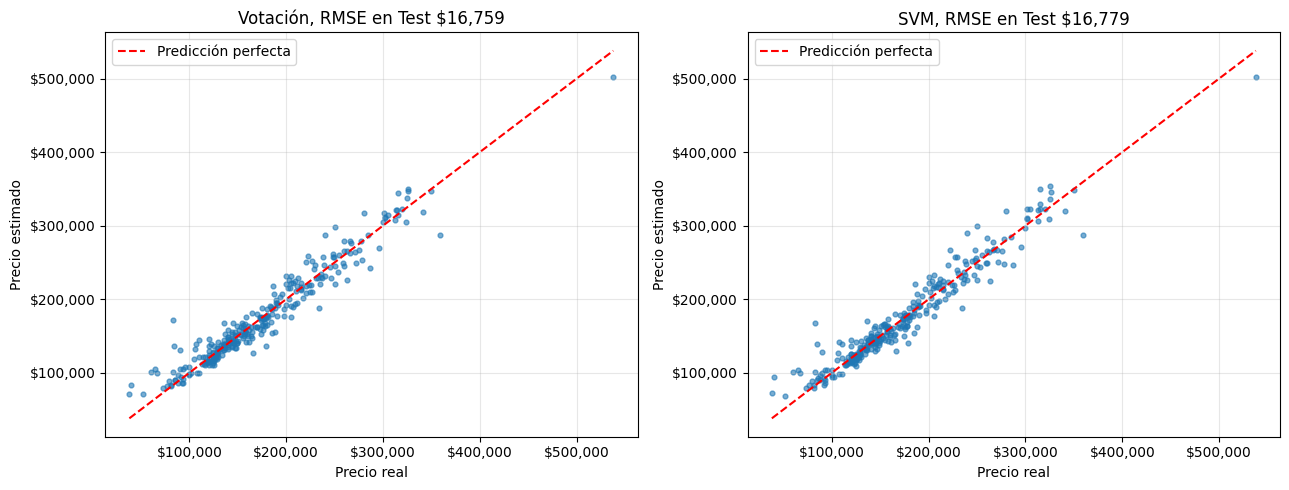

Votación, casas de Test con error menor a 10%: 80%
Votación, casas de Test con error mayor a 20%: 6%


,MAE,MAPE
Precio real,,
Más baratas,"$10,747",12.2%
Precio medio,"$9,180",5.5%
Más caras,"$15,114",6.1%


,Precio real,Precio estimado,SaleCondition,Error,Error relativo
632,"$82,500","$171,121",Family,"$88,621",107%
608,"$359,100","$287,447",Alloca,"$-71,653",-20%
1453,"$84,500","$135,768",Abnorml,"$51,268",61%
4,"$250,000","$298,002",Normal,"$48,002",19%
384,"$240,000","$287,117",Normal,"$47,117",20%


In [40]:
# Precio real contra precio estimado en Test con el modelo recomendado y con el mejor modelo individual.

fig, ejes = plt.subplots(1, 2, figsize=(13, 5))
for eje, nombre in zip(ejes, [RECOMENDADO, mejor_nombre]):
  pred = modelos[nombre].predict(X_test)
  eje.scatter(y_test, pred, s=12, alpha=0.6)
  limites = [y_test.min(), y_test.max()]
  eje.plot(limites, limites, color='red', linestyle='--', label='Predicción perfecta')
  eje.set_title('%s, RMSE en Test $%s' % (nombre, format(round(root_mean_squared_error(y_test, pred)), ',')))
  eje.set_xlabel('Precio real')
  eje.set_ylabel('Precio estimado')
  eje.xaxis.set_major_formatter('${x:,.0f}')
  eje.yaxis.set_major_formatter('${x:,.0f}')
  eje.legend()
  eje.grid(alpha=0.3)
plt.tight_layout()
plt.show()

errores = pd.DataFrame({'Precio real': y_test, 'Precio estimado': modelos[RECOMENDADO].predict(X_test),
                        'SaleCondition': X_test['SaleCondition']})
errores['Error'] = errores['Precio estimado'] - errores['Precio real']
errores['Error relativo'] = errores['Error'] / errores['Precio real']
print('%s, casas de Test con error menor a 10%%: %.0f%%' % (RECOMENDADO, 100 * (errores['Error relativo'].abs() < 0.10).mean()))
print('%s, casas de Test con error mayor a 20%%: %.0f%%' % (RECOMENDADO, 100 * (errores['Error relativo'].abs() > 0.20).mean()))

# Error según el precio de la casa, en tres grupos del mismo tamaño.
tercios = pd.qcut(errores['Precio real'], 3, labels=['Más baratas', 'Precio medio', 'Más caras'])
display(errores.groupby(tercios, observed=True)
        .agg(MAE=('Error', lambda s: s.abs().mean()), MAPE=('Error relativo', lambda s: s.abs().mean()))
        .style.format({'MAE': '${:,.0f}', 'MAPE': '{:.1%}'}))

# Las cinco casas con el error más grande y el tipo de venta.
(errores.reindex(errores['Error'].abs().sort_values(ascending=False).index).head(5)
   .style.format({'Precio real': '${:,.0f}', 'Precio estimado': '${:,.0f}', 'Error': '${:,.0f}', 'Error relativo': '{:.0%}'}))

### **Respuesta**

En Test la votación y la SVM sola quedan prácticamente empatadas, con 16,759 y 16,779 dólares de RMSE, una diferencia de 20 dólares. En MAE la SVM sola es mejor por 171 dólares, y en MAPE las dos tienen 8.0%. El apilamiento queda en 17,353, mejor que Ridge y XGBoost pero peor que las otras dos. Todos los errores de Test son más bajos que los de validación porque son solo 292 casas y les tocaron menos casas difíciles, así que lo que cuenta es la comparación entre modelos y no la cifra absoluta.

Recomendamos la votación, aunque su ventaja es pequeña. En validación cruzada, que es la medición con la que elegimos los modelos, es la mejor, con 604 dólares menos que la SVM (2.7%). En Test esa ventaja no se repitió, pero tampoco se invirtió. Combina tres modelos de tipo distinto, así que depende menos de los errores de uno solo, y cuesta prácticamente lo mismo: se entrena en un segundo y no tiene hiperparámetros propios. La SVM sola es una alternativa igual de válida si se prefiere lo más sencillo, porque en Test empata en RMSE y tiene mejor MAE. El apilamiento no se justifica aquí. Tarda más, es más difícil de explicar y no mejoró a la votación en ninguna de las dos mediciones. Es probable que con 1,166 casas el combinador no tenga suficientes datos para aprender pesos mejores que un promedio simple.

Con la votación, el 80% de las casas de Test tiene un error menor al 10% de su precio y solo el 6% tiene un error mayor al 20%. En dólares se equivoca más en las casas caras, con unos 15,100 dólares en promedio, pero en porcentaje se equivoca más en las baratas, con 12.2% contra 5.5% en las de precio medio. Tres de los cinco errores más grandes son ventas que no son de mercado: una venta entre familiares, una asignación entre propiedades ligadas y una venta anormal como un remate, que en los datos aparecen como `Family`, `Alloca` y `Abnorml`. En esas ventas el precio no depende solo de la casa.

# **Reportes**

**16.** Realizar dos reportes finales sobre qué decisión tomar.

* **a.** Un reporte para tu equipo técnico indicando las decisiones que se deben tomar con base a las métricas, ajuste de los modelos, costo computacional, mantenimiento de la solución.
* **b.** Un reporte para el director de la empresa inmobiliaria con base a los beneficios, riesgos y costos y de manera no técnica.

### **Respuesta**

**Para:** Equipo técnico

**Asunto:** Modelo recomendado para valuar casas y cómo mantenerlo

Recomendamos llevar a producción la votación de la SVM, Ridge y XGBoost, con el mismo Pipeline de preprocesamiento de este cuaderno.

1. Es el mejor modelo en RMSE en validación cruzada, con 21,856 dólares, y en Test queda prácticamente empatado con la SVM sola (16,759 contra 16,779). En Test su MAE es de 11,719 dólares, su R² de 0.937 y su MAPE de 8.0%, y el 80% de las casas tiene un error menor al 10%.
2. Los hiperparámetros de los tres modelos se eligieron con validación cruzada de 5 pliegues sin tocar Test. Ridge usa `alpha` de 3, la SVM `C` de 10, `epsilon` de 0.05 y `gamma` de 0.0005, y XGBoost 600 árboles de profundidad 3 con tasa de aprendizaje de 0.05. Ninguno está subentrenado. XGBoost es el único con una brecha grande entre entrenamiento y validación, y al promediarlo con los otros dos ese riesgo baja.
3. El costo computacional es bajo. La votación se entrena en segundos en una laptop y predice cientos de casas en milisegundos. Todo el cuaderno, con las búsquedas de hiperparámetros de los seis modelos, corre en unos minutos. No recomendamos el apilamiento, porque tarda más y no mejoró el resultado.
4. Hay que guardar el Pipeline completo, con preprocesamiento y modelos, en un solo archivo versionado, para que en producción los datos se transformen igual que al entrenar.
5. Antes de predecir hay que validar cada casa nueva. Las categorías que no existían caen en la columna de poco frecuentes, pero los valores fuera del rango de entrenamiento, como casas de más de 4,000 pies cuadrados, y las ventas que no son de mercado deben ir a revisión de un valuador.
6. Hay que medir cada mes el MAE y el MAPE contra los precios reales de venta y reentrenar cuando el MAPE pase de 10%, además de repetir la búsqueda de hiperparámetros cuando se acumulen muchas ventas nuevas.
7. Los datos son de Ames, Iowa, entre 2006 y 2010. Antes de usar el modelo en otro mercado hay que reentrenarlo con ventas de esa zona.

Si se necesita algo más simple, hay dos alternativas: la SVM sola, que en Test empata con la votación y tiene mejor MAE, y Ridge, que queda a unos 1,300 dólares de RMSE en Test y cuyos coeficientes se pueden leer directamente.

### **Respuesta**

**Para:** Director de la inmobiliaria

**Asunto:** Modelo para estimar el precio de venta de las casas

Recomendamos usar el modelo como apoyo para los valuadores y no como reemplazo.

El modelo estima en segundos el precio de una casa a partir de sus características, como el tamaño, la calidad de los acabados, la antigüedad y el barrio. Lo probamos con 292 casas que no vio al aprender. En promedio se equivocó por unos 11,700 dólares, alrededor del 8% del precio de la casa, y en 8 de cada 10 casas el error fue menor al 10%. Sin modelo, estimar siempre el precio promedio se equivoca en promedio por más de 53,000 dólares.

El modelo funciona como un comité de tres expertos: tres métodos distintos estiman el precio por separado y se toma el promedio de sus respuestas. Así, cuando uno se equivoca en una casa, los otros dos compensan parte de ese error.

Esto permite valuar más rápido, dar a los clientes un precio de referencia desde la primera visita y detectar casas publicadas muy por encima o por debajo de su valor. El modelo además usa los mismos criterios que un valuador. Lo que más pesa es la superficie de la casa, luego la calidad y la antigüedad, y después el terreno y el sótano.

Hay cuatro riesgos que cuidar.

1. El modelo aprendió con ventas de Ames, Iowa, entre 2006 y 2010. Antes de usarlo hay que volver a entrenarlo con ventas recientes de nuestra zona.
2. Se equivoca más en las casas más baratas, donde el error promedio es del 12% del precio, y en ventas que no son de mercado, como ventas entre familiares o remates. Esos casos deben pasar siempre por un valuador.
3. El mercado cambia. Hay que revisar cada mes qué tan bien acierta y actualizarlo cuando empiece a fallar.
4. El modelo depende de que los datos de cada casa estén completos y bien capturados. Si recibe un área o una calidad mal registradas, da un precio equivocado sin avisar, así que hay que validar los datos antes de estimar.

El costo es bajo. El modelo corre en una computadora normal y se actualiza en minutos. El costo principal es el tiempo de una persona para mantener los datos al día, revisar los resultados cada mes y atender las casas que el modelo mande a revisión.

Proponemos una prueba de tres meses en la que el modelo dé un precio de referencia y los valuadores lo comparen con su propia estimación, antes de usarlo con clientes.

# **Conclusiones**

Incluyan los comentarios y conclusiones de esta actividad. En particular, respondan sobre los siguientes puntos:

* ¿En qué casos el uso de LLMs fue de mayor provecho?
* ¿En cuáles casos la intervención como expertos en combinación con los LLM fue importante para alcanzar con los objetivos propuestos?


**17.** Incluyan sus conclusiones de la actividad.

### **Conclusiones**

Lo que más nos llevamos de esta actividad es que las decisiones sobre los datos pesaron más que la elección del modelo. Leer la descripción de las variables cambió todo el manejo de los datos perdidos, porque en la mayoría NA quería decir que la casa no tenía esa característica y no que faltara el dato. Imputar con la moda habría inventado albercas y cocheras. Transformar el precio con logaritmo, quitar las dos ventas parciales atípicas y codificar las calidades con su orden ayudaron más que cualquier ajuste fino de hiperparámetros.

También nos sorprendió que los modelos más sencillos quedaran arriba. Ridge y una SVM con un kernel muy suave le ganaron a XGBoost, al bosque aleatorio y a la red neuronal, porque con el precio en logaritmo la relación es casi lineal y con 1,166 casas los modelos flexibles no tienen mucho más que aprender. Aun así XGBoost sirvió dentro de la votación porque se equivoca de forma distinta. Combinar modelos diferentes mejoró la validación cruzada, aunque en Test la ventaja casi desapareció, y el apilamiento no superó a un promedio simple. Por último, la restricción de valuación estática nos hizo pensar en qué información va a existir cuando se use el modelo: el año de venta ayudaría a predecir estos datos, pero no sirve para valuar una casa hoy.

**¿En qué casos el uso de LLMs fue de mayor provecho?**

* Para escribir más rápido el código repetitivo: el Pipeline con sus dos versiones de preprocesamiento, las rejillas de hiperparámetros, la función de las curvas de aprendizaje y las tablas de métricas.
* Para repasar cómo funcionan `VotingRegressor` y `StackingRegressor`.
* Para comparar entre los integrantes distintas versiones del mismo análisis y detectar diferencias, como la decisión sobre las casas atípicas o qué hacer con `MoSold`.

**¿En cuáles fue importante nuestra intervención como expertos?**

* En las decisiones que dependen de entender los datos y el negocio: revisar la descripción de cada variable para saber qué significa un NA y verificarlo contra otra columna, decidir qué casas atípicas quitar y justificar qué hacer con los años y con el mes.
* En leer los resultados con criterio. Por ejemplo, una diferencia de 233 dólares entre el tercer y el cuarto modelo es casi un empate, y la mejora de 2.7% de la votación en validación no se repitió en Test, así que la recomendamos con esa salvedad y con la SVM sola como alternativa.
* En revisar las gráficas. Las curvas de aprendizaje no tenían su primer punto, y al investigarlo encontramos que el imputador descartaba la columna `PoolQC` cuando una muestra pequeña no tenía ninguna alberca. El código corría sin errores, así que sin revisar las gráficas no se habría notado.
* En verificar lo que proponía el LLM. Las cifras salen de nuestras propias ejecuciones, y comparando versiones notamos detalles que el código no reportaba, como que los mejores hiperparámetros de la SVM quedaron en el borde de la rejilla.

### **Referencias**

Breiman, L. (1996). Stacked regressions. *Machine Learning, 24*(1), 49–64. https://doi.org/10.1007/BF00117832

Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5–32. https://doi.org/10.1023/A:1010933404324

Chen, T., & Guestrin, C. (2016). XGBoost: A scalable tree boosting system. En *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining* (pp. 785–794). https://doi.org/10.1145/2939672.2939785

De Cock, D. (2011). Ames, Iowa: Alternative to the Boston housing data as an end of semester regression project. *Journal of Statistics Education, 19*(3). https://doi.org/10.1080/10691898.2011.11889627

Drucker, H., Burges, C. J. C., Kaufman, L., Smola, A., & Vapnik, V. (1997). Support vector regression machines. En M. C. Mozer, M. I. Jordan y T. Petsche (Eds.), *Advances in Neural Information Processing Systems 9* (pp. 155–161). MIT Press.

Friedman, J. H. (2001). Greedy function approximation: A gradient boosting machine. *The Annals of Statistics, 29*(5), 1189–1232. https://doi.org/10.1214/aos/1013203451

Hoerl, A. E., & Kennard, R. W. (1970). Ridge regression: Biased estimation for nonorthogonal problems. *Technometrics, 12*(1), 55–67. https://doi.org/10.1080/00401706.1970.10488634

Montoya, A., & DataCanary. (2016). *House prices: Advanced regression techniques* [Competencia]. Kaggle. https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830. http://jmlr.org/papers/v12/pedregosa11a.html

Wolpert, D. H. (1992). Stacked generalization. *Neural Networks, 5*(2), 241–259. https://doi.org/10.1016/S0893-6080(05)80023-1

Yeo, I.-K., & Johnson, R. A. (2000). A new family of power transformations to improve normality or symmetry. *Biometrika, 87*(4), 954–959. https://doi.org/10.1093/biomet/87.4.954

# **Anexo**

**Incluir a continuación los prompts que consideren hayan sido los más importantes, así como el nombre del modelo LLM utilizado.**

### **Prompts**

**Modelos LLM utilizados por el equipo:** Claude (Anthropic), con los modelos Claude Opus 5 y Claude Opus 5.5, a través de claude.ai y de Claude Code, y OpenAI Codex (GPT-6.1) para comparar resultados y validaciones.

Estos fueron los prompts más importantes.

* "Tengo el train.csv del reto House Prices de Kaggle. Arma un Pipeline de sklearn con ColumnTransformer que impute y transforme las variables numéricas, ordinales y nominales sin filtrar información, con una versión para los modelos lineales, el MLP y la SVM y otra para los árboles, y que entrene con log(SalePrice) pero calcule las métricas en dólares."

* "Escribe una función que ajuste los hiperparámetros con GridSearchCV o RandomizedSearchCV usando el RMSE con validación cruzada de 5 pliegues, que guarde RMSE, MAE, R², MAPE y el tiempo de entrenamiento en una tabla, y otra función que grafique la curva de aprendizaje de cada modelo."

* "Explícame en qué se diferencian VotingRegressor y StackingRegressor de sklearn y cómo evito que el combinador del apilamiento aprenda de predicciones sobre casas que los modelos ya vieron."

* "Mis curvas de aprendizaje no muestran el primer punto en ningún modelo. ¿Por qué learning_curve podría estar fallando con las muestras más pequeñas?"

* "Revisa `data_description.txt` y dime en qué variables el valor "NA" significa "la casa no tiene ese elemento" y en cuáles significa dato perdido de verdad. Para cada una, verifica tu conclusión contra otra columna del conjunto."

* "No elijas la opción de `MoSold` por lo que suene mejor. Evalúa las cuatro con validación cruzada y reporta la desviación estándar junto con la media para saber si la diferencia es real o es ruido."